**Data Handling**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("students_cleaned.csv")

# Display first five records
print("First Five Records:")
print(df.head())

# Display dataset information
print("\nDataset Information:")
df.info()

# Display number of rows and columns
print("\nDataset Shape:")
print(df.shape)

# Display column names
print("\nDataset Columns:")
print(df.columns)

First Five Records:
   Student_ID     Name  Age  Marks Department
0         101  Yasasvi   21     85        CSE
1         102    Rahul   22     72        ECE
2         103    Priya   21     91        CSE
3         104    Arjun   21     79         IT
4         105    Sneha   22     78        ECE

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Student_ID  30 non-null     int64
 1   Name        30 non-null     str  
 2   Age         30 non-null     int64
 3   Marks       30 non-null     int64
 4   Department  30 non-null     str  
dtypes: int64(3), str(2)
memory usage: 1.5 KB

Dataset Shape:
(30, 5)

Dataset Columns:
Index(['Student_ID', 'Name', 'Age', 'Marks', 'Department'], dtype='str')


**Data Cleaning**

In [2]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Convert columns into numeric values
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["Marks"] = pd.to_numeric(df["Marks"], errors="coerce")

# Fill missing values
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Marks"] = df["Marks"].fillna(df["Marks"].mean())

# Convert values into integers
df["Age"] = df["Age"].astype(int)
df["Marks"] = df["Marks"].round().astype(int)

# Remove duplicate records
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

print("\nDataset After Cleaning:")
print(df)

print("\nRemaining Missing Values:")
print(df.isnull().sum().sum())

print("\nRemaining Duplicate Records:")
print(df.duplicated().sum())

print("\nTotal Records After Cleaning:", len(df))

Missing Values:
Student_ID    0
Name          0
Age           0
Marks         0
Department    0
dtype: int64

Dataset After Cleaning:
    Student_ID     Name  Age  Marks Department
0          101  Yasasvi   21     85        CSE
1          102    Rahul   22     72        ECE
2          103    Priya   21     91        CSE
3          104    Arjun   21     79         IT
4          105    Sneha   22     78        ECE
5          106    Kiran   20     79         IT
6          107    Divya   21     95        CSE
7          108    Manoj   21     55        ECE
8          109   Anjali   20     82         IT
9          110    Vijay   22     68        CSE
10         111     Neha   21     89        ECE
11         112     Ravi   22     74         IT
12         113    Meena   20     93        CSE
13         114  Karthik   21     61        ECE
14         115    Pooja   22     86         IT
15         116     Ajay   20     79        CSE
16         117   Swathi   21     96        ECE
17         118    Va

**Data Analysis**

In [3]:
# Calculate average marks
average_marks = df["Marks"].mean()

# Find highest and lowest marks
highest_marks = df["Marks"].max()
lowest_marks = df["Marks"].min()

# Count passed and failed students
passed_students = (df["Marks"] >= 35).sum()
failed_students = (df["Marks"] < 35).sum()

# Display results
print("STUDENT PERFORMANCE ANALYSIS")

print("Total Students:", len(df))
print("Average Marks:", round(average_marks, 2))
print("Highest Marks:", highest_marks)
print("Lowest Marks:", lowest_marks)
print("Number of Passed Students:", passed_students)
print("Number of Failed Students:", failed_students)

STUDENT PERFORMANCE ANALYSIS
Total Students: 30
Average Marks: 78.83
Highest Marks: 98
Lowest Marks: 54
Number of Passed Students: 30
Number of Failed Students: 0


**Chart 1: Average Marks by Department — Bar Chart**

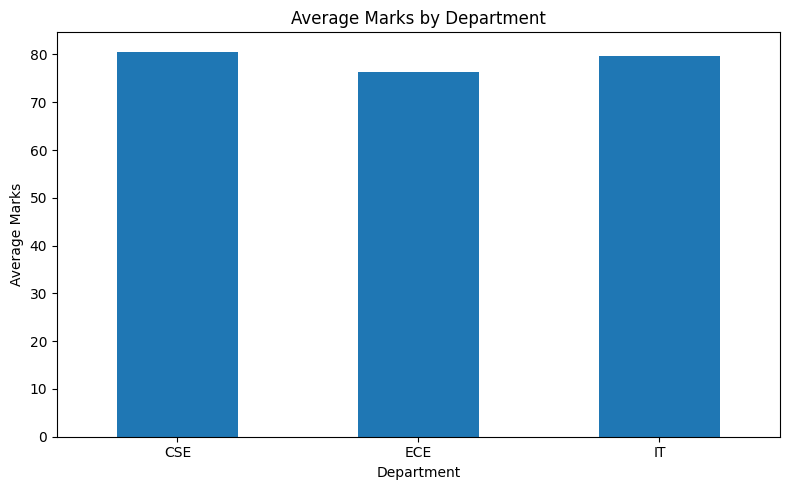

In [4]:
# Calculate average marks by department
department_marks = df.groupby("Department")["Marks"].mean()

# Create bar chart
plt.figure(figsize=(8, 5))
department_marks.plot(kind="bar")

plt.title("Average Marks by Department")
plt.xlabel("Department")
plt.ylabel("Average Marks")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Chart 2: Distribution of Student Marks — Histogram**

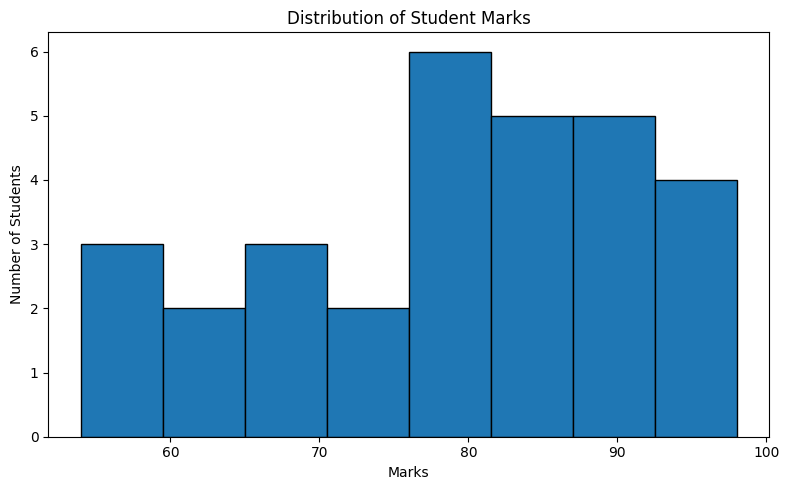

In [5]:
# Create histogram
plt.figure(figsize=(8, 5))
plt.hist(df["Marks"], bins=8, edgecolor="black")

plt.title("Distribution of Student Marks")
plt.xlabel("Marks")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

**Chart 3: Pass and Fail Students — Bar Chart**

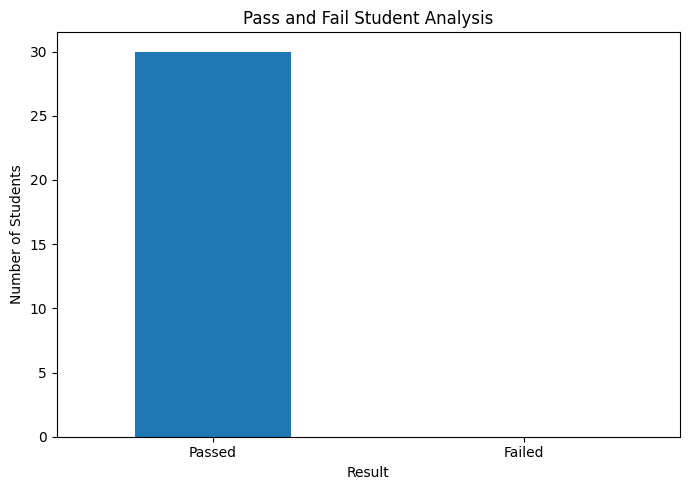

In [6]:
# Calculate pass and fail counts
pass_fail = pd.Series({
    "Passed": (df["Marks"] >= 35).sum(),
    "Failed": (df["Marks"] < 35).sum()
})

# Create bar chart
plt.figure(figsize=(7, 5))
pass_fail.plot(kind="bar")

plt.title("Pass and Fail Student Analysis")
plt.xlabel("Result")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()